# 01 - Fundamentos de Bagging y Random Forest en Regresión

## Curso de Machine Learning: Modelos de Regresión

En el módulo anterior estudiamos los **Árboles de Decisión para Regresión (CART)** y observamos su principal debilidad estructural: su **alta varianza**. Pequeñas fluctuaciones en los datos de entrenamiento pueden dar lugar a árboles con estructuras radicalmente diferentes y superficies de predicción escalonadas.

El algoritmo **Random Forest Regressor (Leo Breiman, 2001)** soluciona esta limitación aplicando dos principios simultáneos:
1. **Bagging (Bootstrap Aggregating)**: Promediar las predicciones de $B$ árboles entrenados sobre muestras bootstrap con reemplazo.
2. **Feature Subsampling**: Aleatorizar el subconjunto de características evaluadas en cada división para descorrelacionar los estimadores.

---

### Contenidos
1. Limitaciones de Varianza del Árbol de Regresión Individual
2. Formulación Matemática de Bagging en Variables Continuas
3. Doble Aleatorización en Random Forest: Muestras y Variables
4. Error Out-Of-Bag ($MSE_{OOB}$) en Regresión
5. Implementación con `RandomForestRegressor` en el Dataset Auto MPG
6. Curva de Convergencia del Error OOB vs. Número de Árboles
7. Conclusiones


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, BaggingRegressor
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
np.random.seed(42)
print("Bibliotecas importadas y entorno configurado.")


Bibliotecas importadas y entorno configurado.


## 1. Carga del Dataset Auto MPG

Utilizamos el dataset de consumo de combustible vehicular (`auto_mpg.csv`). El objetivo es predecir la eficiencia `mpg` (millas por galón) a partir de atributos físicos del motor y vehículo.


In [9]:
# Carga de datos local
df = pd.read_csv("../../../data/auto_mpg.csv")
print(f"Dimensiones del dataset: {df.shape}")
print(df.head(4))

# Seleccion de variables predictoras numericas y objetivo
features = ['cylinders', 'displacement', 'horsepower', 'weight', 'acceleration', 'model_year']
X = df[features]
y = df['mpg']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42
)
print(f"Dimensiones train: {X_train.shape} | test: {X_test.shape}")


Dimensiones del dataset: (392, 9)
    mpg  cylinders  displacement  horsepower  weight  acceleration  \
0  18.0          8         307.0       130.0    3504          12.0   
1  15.0          8         350.0       165.0    3693          11.5   
2  18.0          8         318.0       150.0    3436          11.0   
3  16.0          8         304.0       150.0    3433          12.0   

   model_year origin                       name  
0          70    usa  chevrolet chevelle malibu  
1          70    usa          buick skylark 320  
2          70    usa         plymouth satellite  
3          70    usa              amc rebel sst  
Dimensiones train: (294, 6) | test: (98, 6)


## 2. Bagging y Reducción de Varianza

En un problema de regresión continua, la predicción de un ensamble Bagging es el **promedio aritmético** de las predicciones individuales:

$$\hat{f}_{bag}(\mathbf{x}) = \frac{1}{B} \sum_{b=1}^B f_b(\mathbf{x})$$

Si cada árbol individual tiene varianza $\sigma^2$ y la correlación media entre las predicciones de dos árboles cualesquiera es $\rho$, la varianza del ensamble agregado es:

$$\mathbb{V}ar(\hat{f}_{bag}(\mathbf{x})) = \rho \sigma^2 + \frac{1 - \rho}{B} \sigma^2$$

- Cuando aumentamos el número de estimadores $B$, el segundo término $\frac{1-\rho}{B}\sigma^2 \to 0$.
- Sin embargo, **el término residual $\rho \sigma^2$ no se puede eliminar sólo agregando más árboles**.
- **La innovación de Random Forest**: Al seleccionar solo un subconjunto aleatorio de variables en cada nodo (`max_features`), se **reduce activamente la correlación $\rho$**, disminuyendo drásticamente la varianza total del modelo.


In [7]:
# Comparacion: Arbol Unico vs Bagging vs Random Forest
tree_single = DecisionTreeRegressor(random_state=42).fit(X_train, y_train)
bagging = BaggingRegressor(estimator=DecisionTreeRegressor(), n_estimators=100, random_state=42, n_jobs=-1).fit(X_train, y_train)
rf = RandomForestRegressor(n_estimators=100, max_features='sqrt', random_state=42, n_jobs=-1).fit(X_train, y_train)

r2_tree = r2_score(y_test, tree_single.predict(X_test))
r2_bag = r2_score(y_test, bagging.predict(X_test))
r2_rf = r2_score(y_test, rf.predict(X_test))

rmse_tree = np.sqrt(mean_squared_error(y_test, tree_single.predict(X_test)))
rmse_bag = np.sqrt(mean_squared_error(y_test, bagging.predict(X_test)))
rmse_rf = np.sqrt(mean_squared_error(y_test, rf.predict(X_test)))

print("="*60)
print(f"Arbol Unico      -> R2: {r2_tree:.4f} | RMSE: {rmse_tree:.2f} mpg")
print(f"Bagging Regressor-> R2: {r2_bag:.4f} | RMSE: {rmse_bag:.2f} mpg")
print(f"Random Forest    -> R2: {r2_rf:.4f} | RMSE: {rmse_rf:.2f} mpg")
print("="*60)


Arbol Unico      -> R2: 0.7514 | RMSE: 3.54 mpg
Bagging Regressor-> R2: 0.8763 | RMSE: 2.50 mpg
Random Forest    -> R2: 0.8690 | RMSE: 2.57 mpg


## 3. Estimación Out-Of-Bag ($R^2_{OOB}$ y $MSE_{OOB}$)

Aproximadamente el $36.8\%$ de los datos no participan en el entrenamiento de cada árbol individual (muestras fuera de bolsa). En regresión, el estimador predice cada muestra $i$ usando exclusivamente los árboles que **no** la contuvieron en su réplica bootstrap:

$$MSE_{OOB} = \frac{1}{N} \sum_{i=1}^N (y_i - \hat{f}_{OOB}(\mathbf{x}_i))^2$$

Esto proporciona una estimación honesta y gratuita del error sin requerir un conjunto de validación externo.


C:\Users\HP\anaconda3\Lib\site-packages\sklearn\ensemble\_forest.py:611: UserWarning: Some inputs do not have OOB scores. This probably means too few trees were used to compute any reliable OOB estimates.
  warn(


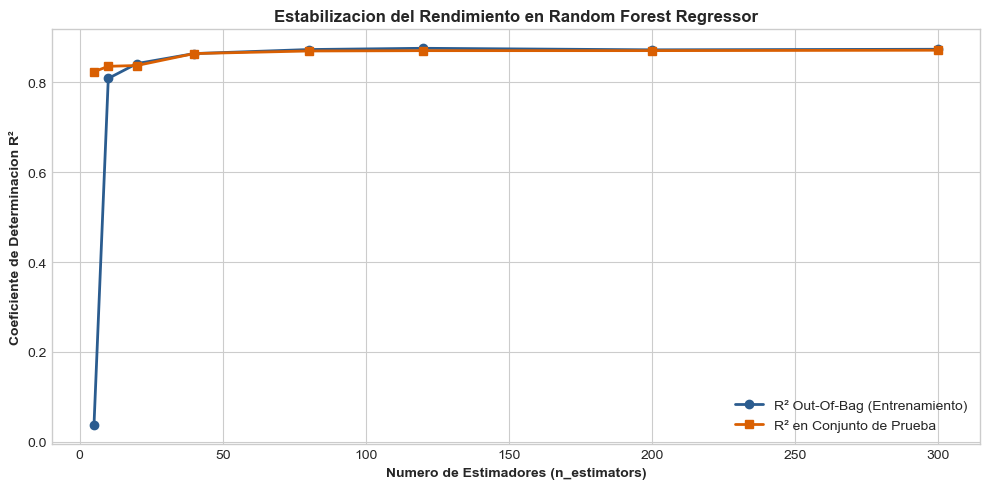

In [8]:
# Curva de convergencia del R2 OOB segun el numero de arboles
n_trees_range = [5, 10, 20, 40, 80, 120, 200, 300]
oob_scores = []
test_scores = []

for n in n_trees_range:
    model = RandomForestRegressor(n_estimators=n, max_features='sqrt', oob_score=True, random_state=42, n_jobs=-1)
    model.fit(X_train, y_train)
    oob_scores.append(model.oob_score_)
    test_scores.append(r2_score(y_test, model.predict(X_test)))

plt.figure(figsize=(10, 5))
plt.plot(n_trees_range, oob_scores, 'o-', color='#2b5c8f', lw=2, label='R² Out-Of-Bag (Entrenamiento)')
plt.plot(n_trees_range, test_scores, 's-', color='#d95f02', lw=2, label='R² en Conjunto de Prueba')
plt.xlabel('Numero de Estimadores (n_estimators)', fontweight='bold')
plt.ylabel('Coeficiente de Determinacion R²', fontweight='bold')
plt.title('Estabilizacion del Rendimiento en Random Forest Regressor', fontweight='bold')
plt.legend()
plt.tight_layout()
plt.show()


## 4. Conclusiones

1. **Reducción de Varianza**: El promedio de múltiples árboles descorrelacionados suaviza los saltos abruptos de un árbol individual.
2. **Submuestreo de Características**: En regresión, la regla empírica estándar es evaluar $m = D$ (todas) o $m = D/3$ o $m = \sqrt{D}$ características en cada partición.
3. **Imposibilidad de Sobreajustar por $n\_estimators$**: Añadir más árboles disminuye la varianza hasta estabilizarse, pero nunca aumenta el sobreajuste.

En el siguiente cuaderno, **02_Hiperparametros_Interpretabilidad_y_PDP.ipynb**, analizaremos el ajuste fino de hiperparámetros, la importancia de variables y los Gráficos de Dependencia Parcial (PDP).
